# Лабораторная работа №2 по ��урсу «Системы искусственного интеллекта»
## Тема: «Продукционная модель представления знаний и механизмы логического вывода»
### Вариант №8: «Отбор кандидатов на вакантное место»

**Цель работы:**
Приобретение умений и навыков реализации пополняемой динамической базы знаний продукционного типа, не включаемой непосредственно в текст программы, с механизмом **обратного логического вывода** (Backward Chaining), исчислением предикатов первого порядка, представлением в виде графа И/ИЛИ, разрешением конфликтов и подсистемой объяснения (вопросы «ПОЧЕМУ?» и «КАК?»).


---
## 1. Импорт библиотек и настройка рабочей среды


In [1]:
import os
import json
from typing import List, Dict, Any, Optional, Tuple, Set, Union

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from expert_system import Term, Predicate, Rule, ProofNode, BackwardChainingEngine
from visualize_graph import build_full_and_or_graph, plot_and_or_graph, plot_partial_proof_graph

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
print('Все библиотеки успешно загружены.')


Все библиотеки успешно загружены.


---
## 2. Формализация предметной области: Отбор кандидатов (Вариант №8)

В рамках варианта №8 решается задача автоматизированного отбора соискателей на IT-позицию на основе многокритериальной оценки:
- **Уровень образования:** профильное высшее или непрофильное;
- **Первичный HR-ск��ининг:** резюме, портфолио, мотивация (да / нет);
- **Опыт работы:** `более_5` лет, `от_3_до_5` лет, `до_3` лет;
- **Техническое собеседование:** `отлично`, `хорошо`, `неудовлетворительно`;
- **Soft Skills:** командная работа и коммуникация (`высокая`, `средняя`, `низкая`);
- **Международная квалификация:** знание английского (B2+) и опыт в распределенных проектах.

### Иерархия целевых гипотез:
1. `принять_senior`: Senior-разработчик / Тимлид;
2. `принять_middle`: Middle-разработчик;
3. `испытательный_срок`: Junior-разработчик с испытательным сроком;
4. `кадровый_резерв`: сильный специалист при нехватке вторичных навыков;
5. `отказ`: несоответствие базовым критериям или непройденное интервью.


---
## 3. Внешняя динамическая база знаний (JSON)
По требованию лабораторной работы база знаний не зашивается в программный код, а хранится во внешних конфигурационных файлах `data/rules.json` и `data/facts.json`.


In [2]:
with open('data/rules.json', 'r', encoding='utf-8') as f:
    rules_data = json.load(f)

print(f'Всего продукционных правил в БЗ: {len(rules_data["rules"])}')
print()
for r in rules_data['rules'][:4]:
    print(f'[{r["id"]}] {r["name"]} (Приоритет: {r["priority"]})')
    print(f'  Антецедент: {r["premises"]}')
    print(f'  Консеквент: {r["conclusion"]["pred"]}{tuple(r["conclusion"]["args"])}')
    print()


Всего продукционных правил в БЗ: 15

[R1] Допуск кандидата к рассмотрению (Приоритет: 10)
  Антецедент: {'and': [{'pred': 'имеет_высшее_образование', 'args': ['?X', 'профильное']}, {'pred': 'прошел_первичный_скрининг', 'args': ['?X', 'да']}]}
  Консеквент: допущен_к_отбору('?X', 'да')

[R2_A] Высокий уровень Hard Skills (Senior) (Приоритет: 20)
  Антецедент: {'and': [{'pred': 'опыт_работы_лет', 'args': ['?X', 'более_5']}, {'pred': 'успешное_тех_интервью', 'args': ['?X', 'отлично']}]}
  Консеквент: уровень_hard_skills('?X', 'высокий')

[R2_B] Высокий уровень Hard Skills (Middle+ с сильной алгоритмической базой) (Приоритет: 15)
  Антецедент: {'and': [{'pred': 'опыт_работы_лет', 'args': ['?X', 'от_3_до_5']}, {'pred': 'успешное_тех_интервью', 'args': ['?X', 'отлично']}, {'pred': 'системное_мышление', 'args': ['?X', 'высокое']}]}
  Консеквент: уровень_hard_skills('?X', 'высокий')

[R3_A] Средний уровень Hard Skills (опыт 3-5 лет, собеседование хорошо) (Приоритет: 10)
  Антецедент: {'and': [

In [3]:
with open('data/facts.json', 'r', encoding='utf-8') as f:
    facts_data = json.load(f)

print('Зарегистрированные кандидаты в базе данных:')
for cand, facts in facts_data['candidates'].items():
    print(f'  - Кандидат "{cand}": {len(facts)} фактов')


Зарегистрированные кандидаты в базе данных:
  - Кандидат "Иванов": 8 фактов
  - Кандидат "Петров": 6 фактов
  - Кандидат "Сидоров": 6 фактов
  - Кандидат "Кузнецов": 3 фактов


---
## 4. Построение и визуализация полного графа И/ИЛИ базы знаний


Saved: images/and_or_graph.png


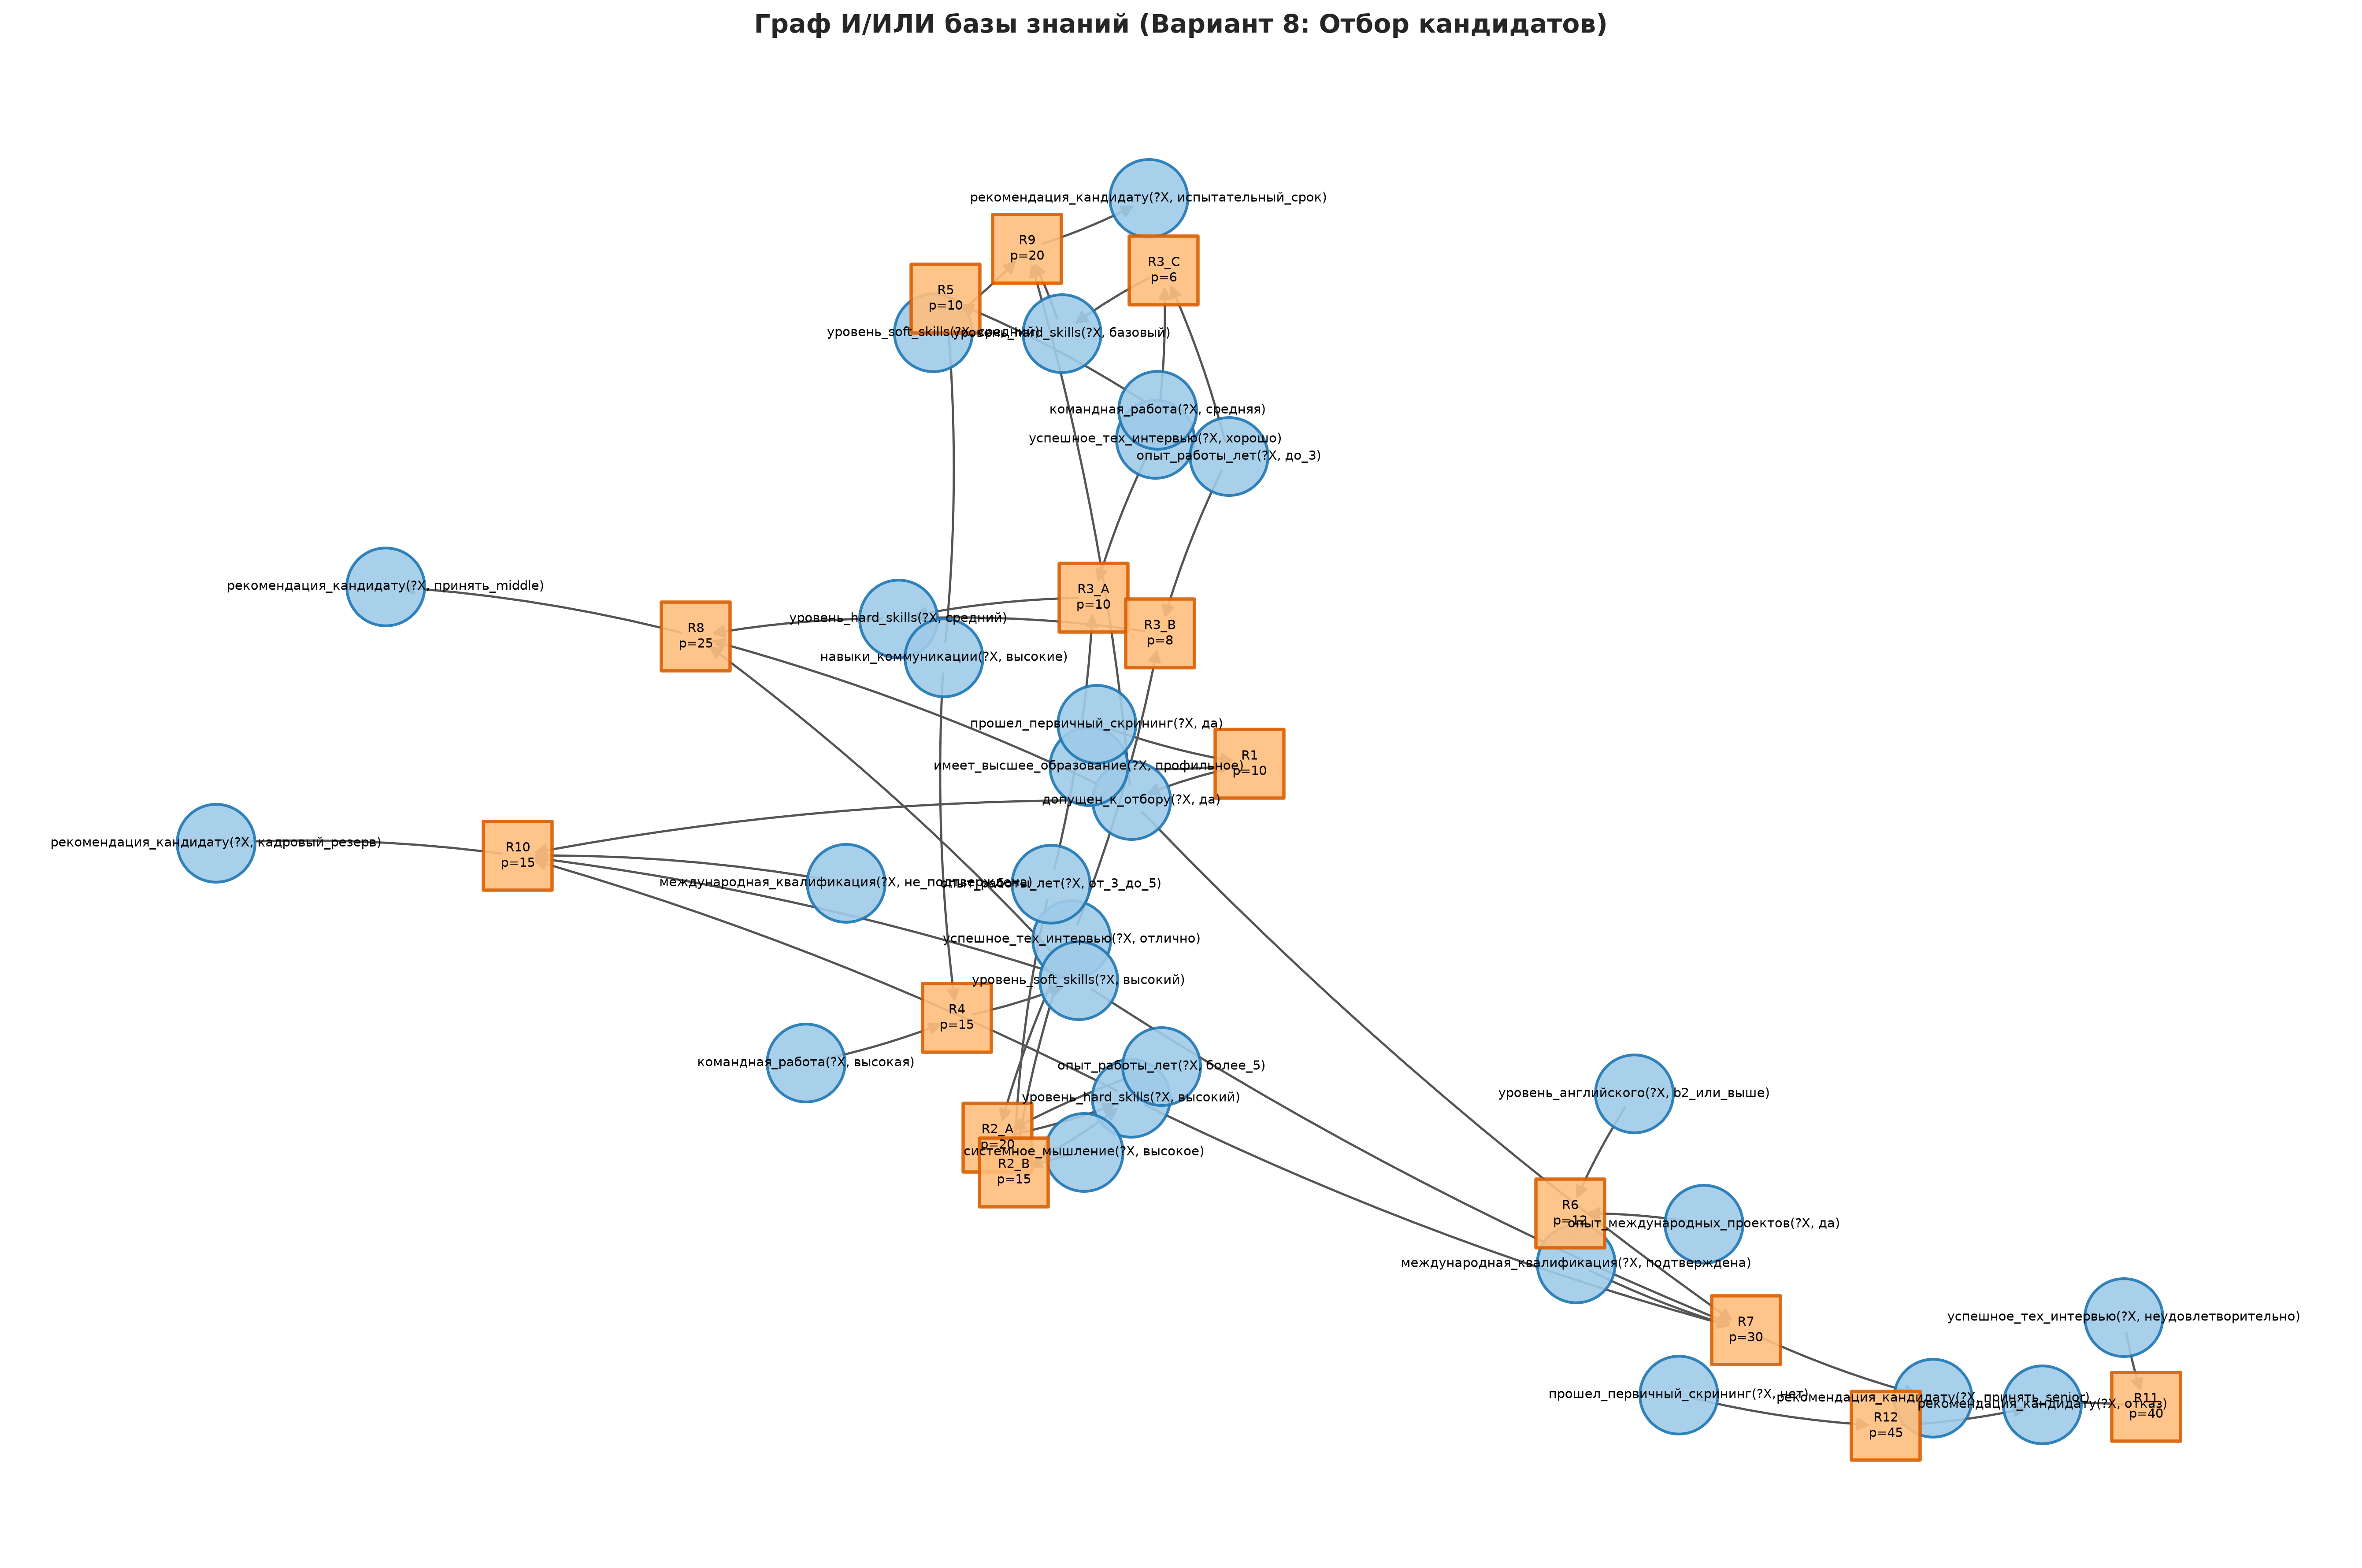

In [4]:
engine = BackwardChainingEngine()
engine.load_rules_from_file('data/rules.json')
G_full = build_full_and_or_graph(engine)
plot_and_or_graph(G_full, 'images/and_or_graph.png')

from IPython.display import Image, display
display(Image('images/and_or_graph.png'))


---
## 5. Механизм обратного вывода: Кандидат Иванов (Senior)


In [5]:
engine_ivanov = BackwardChainingEngine(conflict_resolution_strategy='priority_first')
engine_ivanov.load_rules_from_file('data/rules.json')
engine_ivanov.load_facts_from_file('data/facts.json', candidate_name='Иванов')

goal_ivanov = Predicate('рекомендация_кандидату', ['Иванов', 'принять_senior'])
success, tree = engine_ivanov.prove_goal(goal_ivanov)

print(f'Результат доказательства гипотезы: {"УСПЕХ" if success else "НЕУДАЧА"}')
print('\n--- Протокол обратного вывода на графе ---')
for log_line in engine_ivanov.derivation_log:
    print(log_line)


Результат доказательства гипотезы: УСПЕХ

--- Протокол обратного вывода на графе ---
Загружено 15 правил из файла data/rules.json.
Загружено 8 фактов для кандидата 'Иванов'.
[КОНФЛИКТНЫЙ НАБОР] Для рекомендация_кандидату(Иванов, принять_senior) найдено 1 правил: ['R7'] (порядок после разрешения конфликта: priority_first)
[ПРОБА] Правило R7 (Приоритет 30): Рекомендация на должность Senior-разработчик / Тимлид
  [КОНФЛИКТНЫЙ НАБОР] Для допущен_к_отбору(Иванов, да) найдено 1 правил: ['R1'] (порядок после разрешения конфликта: priority_first)
  [ПРОБА] Правило R1 (Приоритет 10): Допуск кандидата к рассмотрению
    [ФАКТ В БД] Цель имеет_высшее_образование(Иванов, профильное) подтверждена фактом из РП: имеет_высшее_образование(Иванов, профильное)
    [ФАКТ В БД] Цель прошел_первичный_скрининг(Иванов, да) подтверждена фактом из РП: прошел_первичный_скрининг(Иванов, да)
  [УСПЕХ] Цель допущен_к_отбору(Иванов, да) выведена с помощью правила R1!
  [КОНФЛИКТНЫЙ НАБОР] Для уровень_hard_skills(Ива

Saved: images/partial_graph_ivanov.png


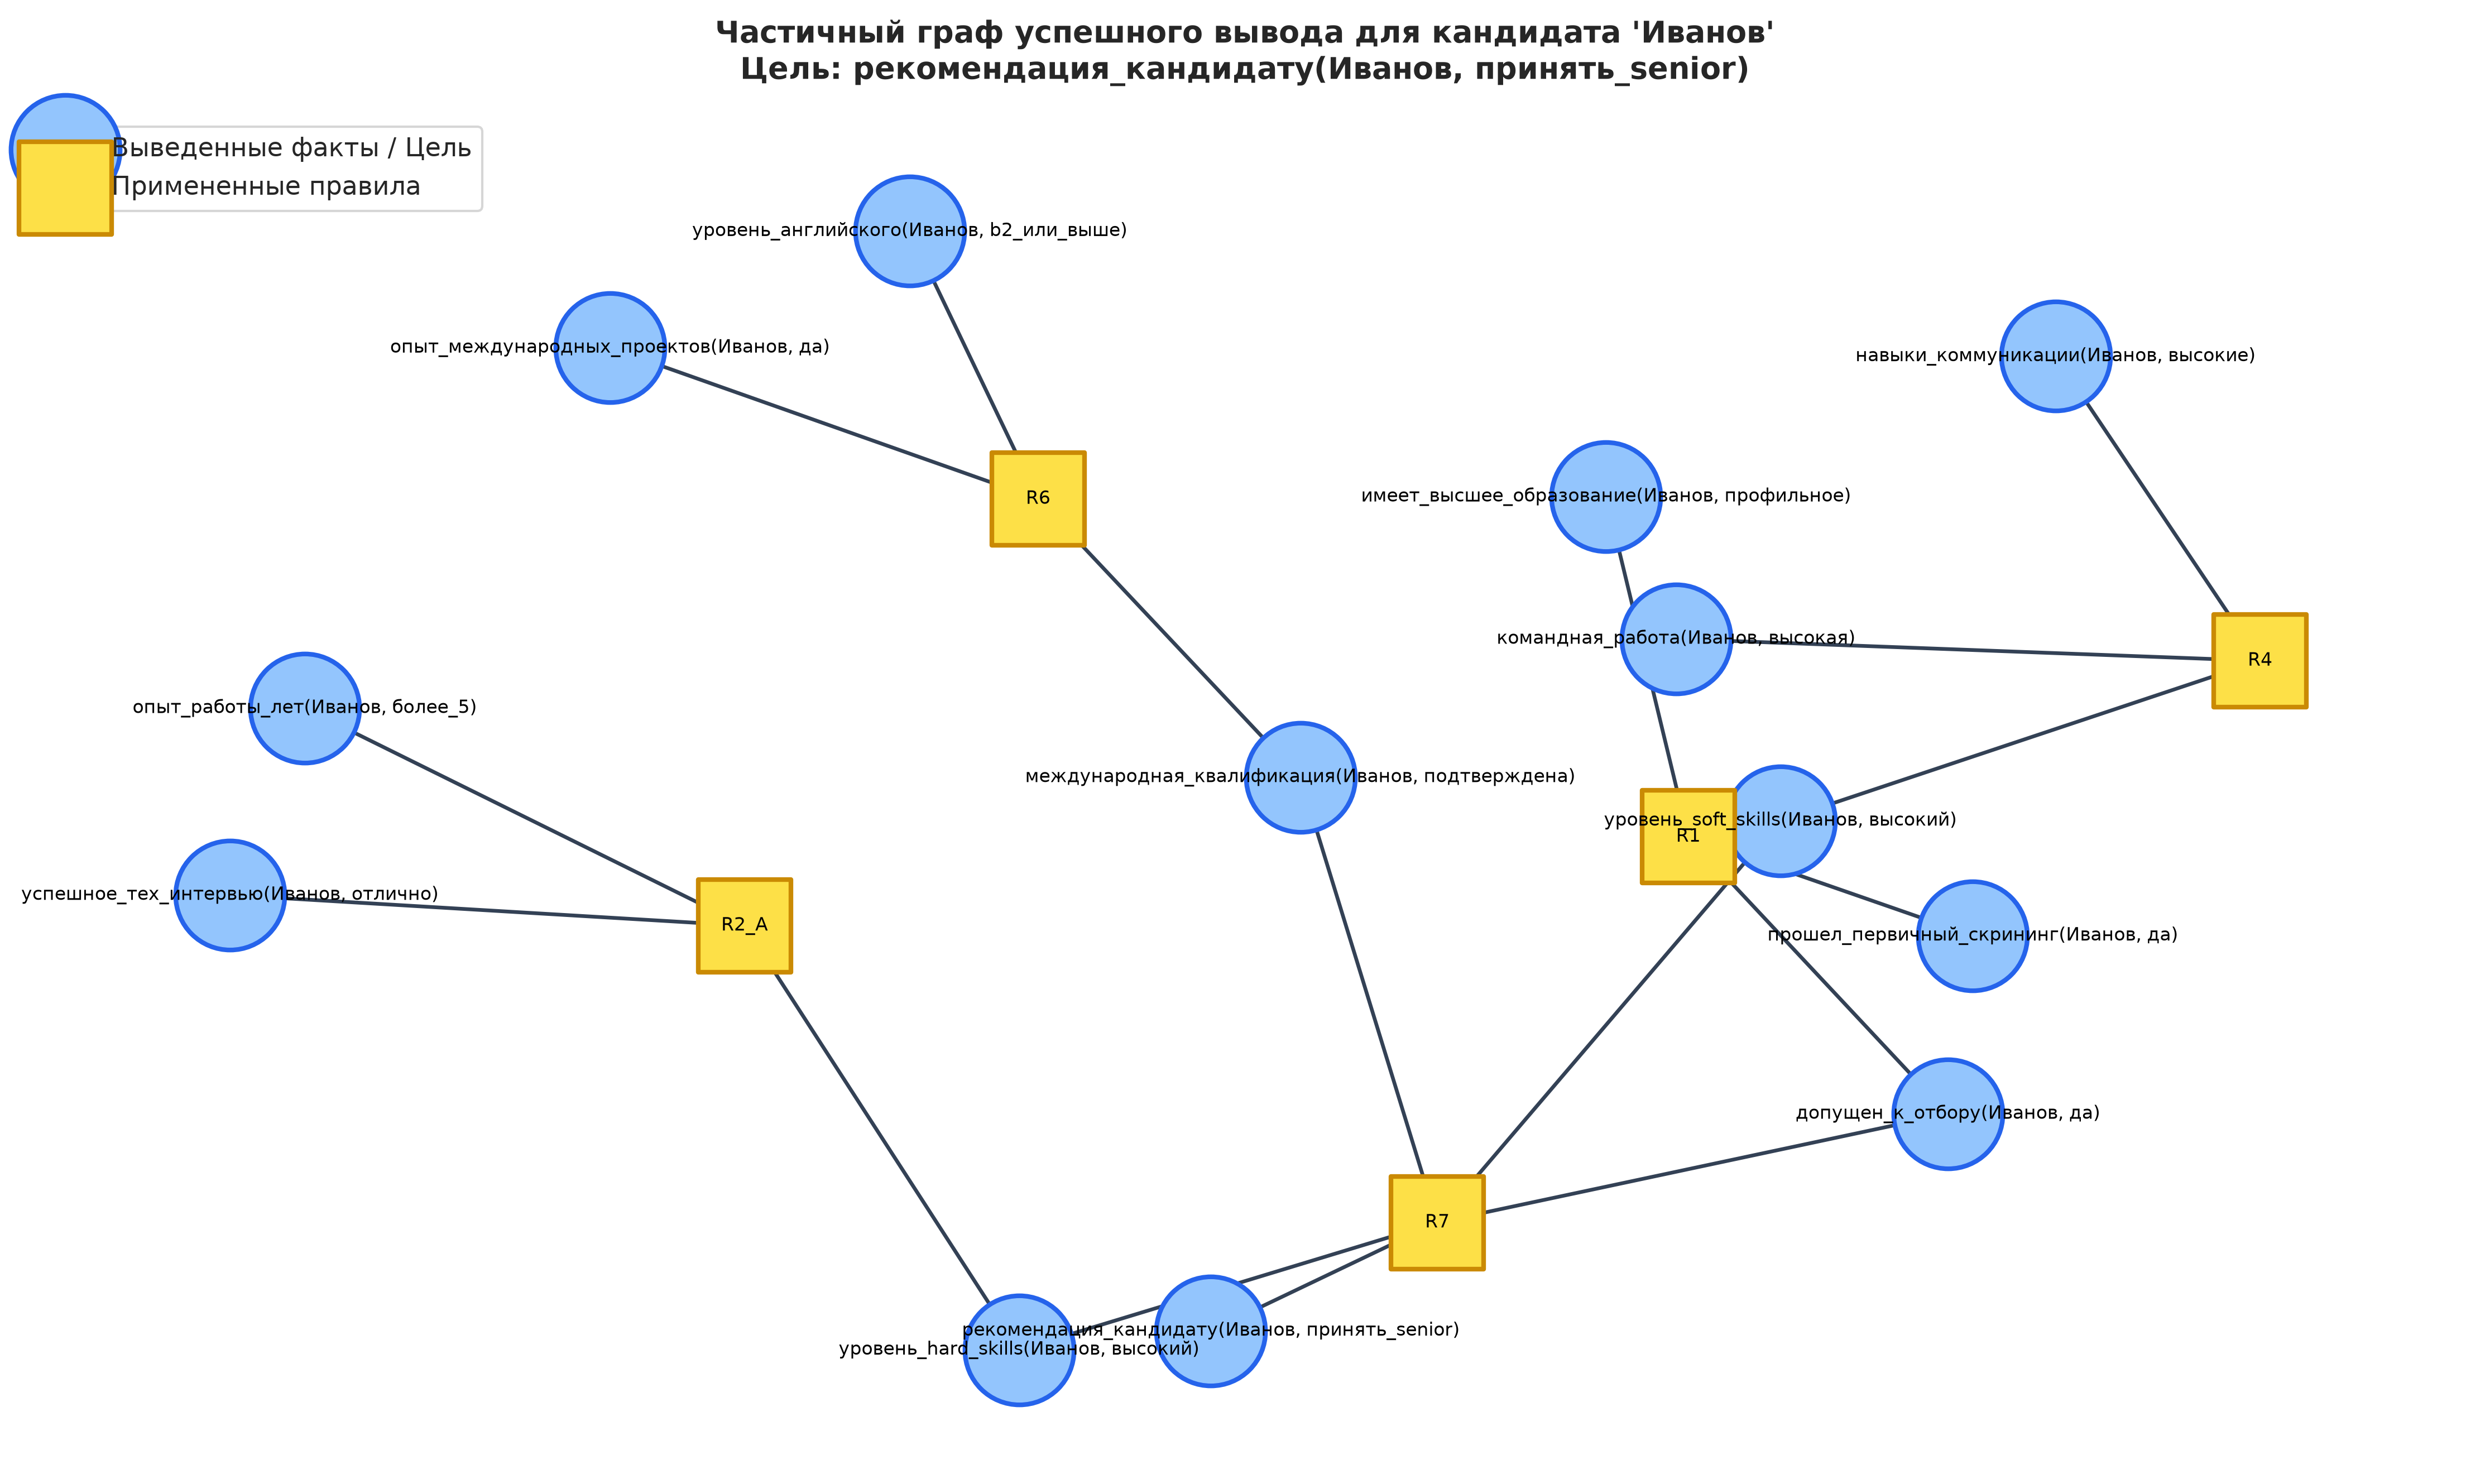

In [6]:
plot_partial_proof_graph(engine_ivanov, 'Иванов', goal_ivanov, 'images/partial_graph_ivanov.png')
display(Image('images/partial_graph_ivanov.png'))


---
## 6. Подсистема объяснения: Ответы на вопросы «ПОЧЕМУ?» и «КАК?»


In [7]:
print('=== ВОПРОС ПОЛЬЗОВАТЕЛЯ: КАК рекомендация_кандидату(Иванов, принять_senior)? ===')
print(engine_ivanov.explain_how('рекомендация_кандидату(Иванов, принять_senior)'))
print()
print('=== ВОПРОС ПОЛЬЗОВАТЕЛЯ: КАК уровень_hard_skills(Иванов, высокий)? ===')
print(engine_ivanov.explain_how('уровень_hard_skills(Иванов, высокий)'))
print()
print('=== ВОПРОС ПОЛЬЗОВАТЕЛЯ: ПОЧЕМУ система запрашивает "опыт_работы_лет"? ===')
print(engine_ivanov.explain_why('опыт_работы_лет'))


=== ВОПРОС ПОЛЬЗОВАТЕЛЯ: КАК рекомендация_кандидату(Иванов, принять_senior)? ===
Утверждение 'рекомендация_кандидату(Иванов, принять_senior)' выведено по правилу [R7]:
Название: Рекомендация на должность Senior-разработчик / Тимлид
Были подтверждены все посылки:
  - допущен_к_отбору(Иванов, да)
  - уровень_hard_skills(Иванов, высокий)
  - уровень_soft_skills(Иванов, высокий)
  - международная_квалификация(Иванов, подтверждена)

=== ВОПРОС ПОЛЬЗОВАТЕЛЯ: КАК уровень_hard_skills(Иванов, высокий)? ===
Утверждение 'уровень_hard_skills(Иванов, высокий)' выведено по правилу [R2_A]:
Название: Высокий уровень Hard Skills (Senior)
Были подтверждены все посылки:
  - опыт_работы_лет(Иванов, более_5)
  - успешное_тех_интервью(Иванов, отлично)

=== ВОПРОС ПОЛЬЗОВАТЕЛЯ: ПОЧЕМУ система запрашивает "опыт_работы_лет"? ===
Вопрос о 'опыт_работы_лет' необходим для проверки условия правила [R2_A]: 'Высокий уровень Hard Skills (Senior)',
чтобы сделать вывод о заключении: 'уровень_hard_skills(?X, высокий)'.


---
## 7. Комплексное тестирование базы знаний на группе кандидатов


In [8]:
candidates = ['Иванов', 'Петров', 'Сидоров', 'Кузнецов']
hypotheses = ['принять_senior', 'принять_middle', 'испытательный_срок', 'кадровый_резерв', 'отказ']

results_table = []

for c in candidates:
    proven_hyp = None
    applied_rule = None
    steps_count = 0
    for hyp in hypotheses:
        eng = BackwardChainingEngine(conflict_resolution_strategy='priority_first')
        eng.load_rules_from_file('data/rules.json')
        eng.load_facts_from_file('data/facts.json', candidate_name=c)
        goal = Predicate('рекомендация_кандидату', [c, hyp])
        succ, node = eng.prove_goal(goal)
        if succ:
            proven_hyp = hyp
            applied_rule = node.rule.id if node.rule else 'БД'
            steps_count = eng.step_counter
            break
            
    results_table.append({
        'Кандидат': c,
        'Решение ЭС': proven_hyp,
        'Ключевое правило': applied_rule,
        'Число шагов доказательства': steps_count
    })

df_res = pd.DataFrame(results_table)
display(df_res)


,Кандидат,Решение ЭС,Ключевое правило,Число шагов доказательства
0,Иванов,принять_senior,R7,13
1,Петров,принять_middle,R8,10
2,Сидоров,испытательный_срок,R9,10
3,Кузнецов,отказ,R12,2


---
## 8. Обнаружение ошибочных правил и обработка неуспешного вывода

В соответствии с требованием п. 2(д, е) методички система выявляет невыполнимые условия в правилах при проверке заведомо ложной гипотезы.


In [9]:
engine_fail = BackwardChainingEngine()
engine_fail.load_rules_from_file('data/rules.json')
engine_fail.load_facts_from_file('data/facts.json', candidate_name='Сидоров')

# Проверяем невыполнимую гипотезу: Сидоров не подходит под Senior
false_goal = Predicate('рекомендация_кандидату', ['Сидоров', 'принять_senior'])
succ, fail_tree = engine_fail.prove_goal(false_goal)

print(f'Статус вывода: {succ}')
print(f'Невыполнимое условие: {fail_tree.failed_condition}')
print('\nФрагмент протокола поиска с фиксацией неуспешных правил:')
for log in engine_fail.derivation_log[-6:]:
    print(log)


Статус вывода: False
Невыполнимое условие: Не удалось доказать ни одно правило для рекомендация_кандидату(Сидоров, принять_senior)

Фрагмент протокола поиска с фиксацией неуспешных правил:
    [НЕУДАЧА] Для цели опыт_работы_лет(Сидоров, более_5) нет правил в БЗ и факта в РП.
    [ОТКЛОНЕНО] Правило R2_A: не выполнено условие опыт_работы_лет(Сидоров, более_5)
  [ПРОБА] Правило R2_B (Приоритет 15): Высокий уровень Hard Skills (Middle+ с сильной алгоритмической базой)
    [НЕУДАЧА] Для цели опыт_работы_лет(Сидоров, от_3_до_5) нет правил в БЗ и факта в РП.
    [ОТКЛОНЕНО] Правило R2_B: не выполнено условие опыт_работы_лет(Сидоров, от_3_до_5)
  [ОТКЛОНЕНО] Правило R7: не выполнено условие уровень_hard_skills(Сидоров, высокий)


---
## 9. Пополнение динамической базы знаний без изменения текста программы

В соответствии с главной целью лабораторной работы («приобретение навыков реализации пополняемой динамической базы знаний, не включаемой непосредственно в текст программы»):
1. Эксперт или инженер по знаниям может добавить новое правило через метод `add_rule()` или файл JSON;
2. Пользователь или HR-менеджер может ввести новый факт через метод `add_fact()` или обновить карточку кандидата;
3. Пополненная база может быть сохранена во внешний файл `save_rules_to_file()` без перезапуска или модификации кода интерпретатора.


In [10]:
print('=== ДЕМОНСТРАЦИЯ ДИНАМИЧЕСКОГО ПОПОЛНЕНИЯ БАЗЫ ЗНАНИЙ ===')
engine_dynamic = BackwardChainingEngine()
engine_dynamic.load_rules_from_file('data/rules.json')
engine_dynamic.load_facts_from_file('data/facts.json', candidate_name='Сидоров')

print(f'Исходное количество правил: {len(engine_dynamic.rules)}')
print(f'Исходное количество фактов для Сидорова: {len(engine_dynamic.working_memory)}')

# Эксперт вводит новое правило (например, для роли Архитектора решений)
new_rule = Rule(
    rule_id='R_ARCHITECT',
    name='Рекомендация на архитектора решений (Solution Architect)',
    premises={'and': [
        Predicate('допущен_к_отбору', ['?X', 'да']),
        Predicate('опыт_проектирования_систем', ['?X', 'да'])
    ]},
    conclusion=Predicate('рекомендация_кандидату', ['?X', 'принять_архитектор']),
    priority=50
)
engine_dynamic.add_rule(new_rule)

# Пользователь сообщает новый факт, полученный на доп. собеседовании
engine_dynamic.add_fact(Predicate('опыт_проектирования_систем', ['Сидоров', 'да']))

print(f'Правил после пополнения: {len(engine_dynamic.rules)}')
print(f'Фактов после пополнения: {len(engine_dynamic.working_memory)}')

# Запуск вывода по новому правилу
new_goal = Predicate('рекомендация_кандидату', ['Сидоров', 'принять_архитектор'])
dyn_success, dyn_tree = engine_dynamic.prove_goal(new_goal)
print(f'Результат логического вывода с новой продукцией: {"УСПЕХ" if dyn_success else "НЕУДАЧА"}')
print()
print('Объяснение решения по новой продукции:')
print(engine_dynamic.explain_how('рекомендация_кандидату(Сидоров, принять_архитектор)'))


=== ДЕМОНСТРАЦИЯ ДИНАМИЧЕСКОГО ПОПОЛНЕНИЯ БАЗЫ ЗНАНИЙ ===
Исходное количество правил: 15
Исходное количество фактов для Сидорова: 6
Правил после пополнения: 16
Фактов после пополнения: 7
Результат логического вывода с новой продукцией: УСПЕХ

Объяснение решения по новой продукции:
Утверждение 'рекомендация_кандидату(Сидоров, принять_архитектор)' выведено по правилу [R_ARCHITECT]:
Название: Рекомендация на архитектора решений (Solution Architect)
Были подтверждены все посылки:
  - допущен_к_отбору(Сидоров, да)
  - опыт_проектирования_систем(Сидоров, да)


---
## 9. Выводы по лабораторной работе

1. **Динамическая база знаний:** Создана масштабируемая архитектура экспертной системы, в которой продукционные правила и факты хранятся во внешних файлах (`rules.json`, `facts.json`), что исключает жесткую завязку на исходный код и позволяет динамически пополнять базу знаний новыми правилами.
2. **Обратный логический вывод (Backward Chaining):** Реализован интерпретатор, работающий от целевых гипотез к фактам рабочей памяти. ��анный подход оптимален для задач отбора и классификации с ограниченным числом возможных исходов.
3. **Разрешение конфликтов:** Использован механизм многокритериального приоритетного упорядочивания конфликтного набора правил (учет статического приоритета и специфичности правила).
4. **Объяснения и протоколирование:** Реализована модель объяснений MYCIN, позволяющая пользователю получать развернутые ответы на вопросы «КАК?» (трассировка вниз к посылкам) и «ПОЧЕМУ?» (подъем вверх к текущей цели), а также строить частичные графы успешного и неуспешного вывода.
